# 🎮 VALORANT Personal Coach

## Notebook 01 — Exploratory Data Analysis (Dev)

### Project Objective

This notebook explores **Dev's VALORANT Competitive match history** before
machine-learning modelling.

The EDA focuses on:

- dataset structure and data quality,
- Win/Loss/Draw balance,
- agent and map usage,
- role distribution,
- performance by agent, map, and role,
- Agent × Map patterns,
- K/D, ACS and DDΔ distributions,
- monthly performance trends,
- and correlations among numerical match statistics.

The final project is **role-aware**. `Role` is derived from the selected
`Agent`.

`TRS (Tracker Score)` is explored only as part of the original raw-data EDA
and is **not intended to be used as a final modelling feature**.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## 1. Load Dev's dataset


In [2]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name in [
    "notebooks",
    "DEVnotebooks",
    "ANUJnotebooks",
]:
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "competitive_matches_dev.xlsx"
)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Place competitive_matches_dev.xlsx inside the project data/ folder."
    )

Project root: c:\Users\HP\Desktop\valorant_personal_coach
Dataset path: c:\Users\HP\Desktop\valorant_personal_coach\data\competitive_matches_dev.xlsx


In [3]:
df = pd.read_excel(
    DATA_PATH,
    sheet_name="Matches",
    header=2,
)

df = df.rename(
    columns={
        "DDΔ (Average Damage Delta per Round)": "DDΔ",
        "HS% (Headshot Percentage)": "HS%",
        "ACS (Average Combat Score)": "ACS",
        "TRS (Tracker Score)": "TRS",
    }
)

helper_columns = [
    column
    for column in df.columns
    if (
        str(column).startswith("Unnamed:")
        or str(column).startswith("http://")
        or str(column).startswith("https://")
    )
]

df = (
    df
    .drop(columns=helper_columns, errors="ignore")
    .dropna(how="all")
    .copy()
)

df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce",
)

df["K/D"] = pd.to_numeric(
    df["K/D"],
    errors="coerce",
)

df["ACS"] = pd.to_numeric(
    df["ACS"],
    errors="coerce",
)

df["DDΔ"] = pd.to_numeric(
    df["DDΔ"],
    errors="coerce",
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1080, 22)


,Match id,Date,Map,Placement,Agent,Team Score,Opponent Score,Result,Win Flag,Score Margin,...,Deaths,Assists,K/D,Kills/Round,Deaths/Round,Assists/Round,DDΔ,HS%,ACS,TRS
0,1,2025-06-21,Pearl,6th,Iso,10,13,Loss,0,-3,...,17,4,0.764706,0.565217,0.739130,0.173913,-25,0.24,174,274
1,2,2025-06-21,Icebox,7th,Neon,13,6,Win,1,7,...,15,3,0.933333,0.736842,0.789474,0.157895,-7,0.31,200,543
2,3,2025-06-22,Lotus,6th,Neon,8,13,Loss,0,-5,...,20,4,0.700000,0.666667,0.952381,0.190476,-34,0.31,198,371
3,4,2025-06-22,Ascent,10th,Killjoy,6,13,Loss,0,-7,...,17,2,0.352941,0.315789,0.894737,0.105263,-71,0.17,115,126
4,5,2025-06-22,Icebox,2nd,Skye,4,0,Win,1,4,...,1,0,4.000000,1.000000,0.250000,0.000000,72,0.40,230,886


## 2. Dataset structure

In [4]:
print("Number of matches:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumns:")
for column in df.columns:
    print(column)

Number of matches: 1080
Number of columns: 22

Columns:
Match id
Date
Map
Placement
Agent
Team Score
Opponent Score
Result
Win Flag
Score Margin
Rounds Played
Kills
Deaths
Assists
K/D
Kills/Round
Deaths/Round
Assists/Round
DDΔ
HS%
ACS
TRS


In [5]:
overview = pd.DataFrame(
    {
        "Data Type": df.dtypes.astype(str),
        "Missing Values": df.isna().sum(),
        "Unique Values": df.nunique(dropna=True),
    }
)

display(overview)

,Data Type,Missing Values,Unique Values
Match id,int64,0,1080
Date,datetime64[us],0,283
Map,str,0,13
Placement,str,0,10
Agent,str,0,26
Team Score,int64,0,18
Opponent Score,int64,0,18
Result,str,0,3
Win Flag,int64,0,2
Score Margin,int64,0,25


## 3. Data quality checks

In [6]:
quality_summary = pd.DataFrame(
    {
        "Check": [
            "Total rows",
            "Duplicate rows",
            "Duplicate Match IDs",
            "Missing dates",
            "Missing maps",
            "Missing agents",
            "Missing results",
        ],
        "Value": [
            len(df),
            int(df.duplicated().sum()),
            int(df["Match id"].duplicated().sum()),
            int(df["Date"].isna().sum()),
            int(df["Map"].isna().sum()),
            int(df["Agent"].isna().sum()),
            int(df["Result"].isna().sum()),
        ],
    }
)

display(quality_summary)

print(
    "Date range:",
    df["Date"].min(),
    "to",
    df["Date"].max(),
)

,Check,Value
0,Total rows,1080
1,Duplicate rows,0
2,Duplicate Match IDs,0
3,Missing dates,0
4,Missing maps,0
5,Missing agents,0
6,Missing results,0


Date range: 2025-06-21 00:00:00 to 2026-09-19 00:00:00


In [7]:
missing_values = (
    df.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

display(missing_values)

,Missing Values
K/D,1
Match id,0
Map,0
Placement,0
Agent,0
Date,0
Team Score,0
Opponent Score,0
Win Flag,0
Result,0


### Note on `Win Flag`

Draws are not part of the later binary Win/Loss target. Therefore, a draw
can legitimately have a missing `Win Flag`.

In [8]:
print("Result counts:")
display(
    df["Result"]
    .value_counts(dropna=False)
    .to_frame("Matches")
)

print("\nWin Flag counts:")
display(
    df["Win Flag"]
    .value_counts(dropna=False)
    .to_frame("Matches")
)

Result counts:


,Matches
Result,
Loss,540
Win,515
Draw,25



Win Flag counts:


,Matches
Win Flag,
0,565
1,515


## 4. Overall result distribution

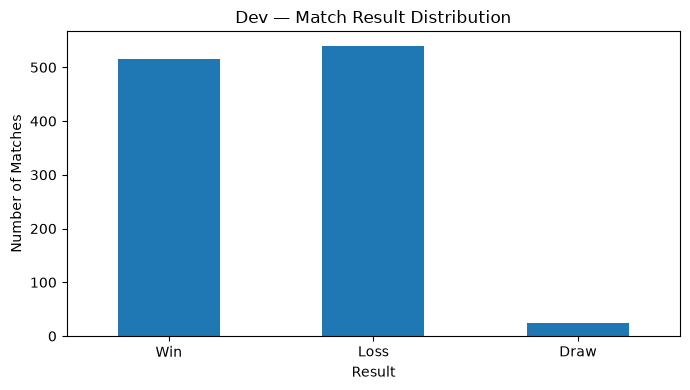

Total matches: 1080
Wins: 515
Losses: 540
Draws: 25
Win rate excluding draws: 48.82%


In [9]:
result_counts = (
    df["Result"]
    .value_counts()
    .reindex(["Win", "Loss", "Draw"])
    .dropna()
)

plt.figure(figsize=(7, 4))
result_counts.plot(kind="bar")
plt.title("Dev — Match Result Distribution")
plt.xlabel("Result")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

wins = int((df["Result"] == "Win").sum())
losses = int((df["Result"] == "Loss").sum())
draws = int((df["Result"] == "Draw").sum())

binary_matches = wins + losses

win_rate = (
    wins / binary_matches
    if binary_matches
    else np.nan
)

print("Total matches:", len(df))
print("Wins:", wins)
print("Losses:", losses)
print("Draws:", draws)
print(
    "Win rate excluding draws:",
    f"{win_rate:.2%}",
)

## 5. Agent usage

,Matches
Agent,
Neon,739
Chamber,55
Reyna,55
Astra,45
Jett,45
Omen,20
Clove,18
Phoenix,16
Iso,15


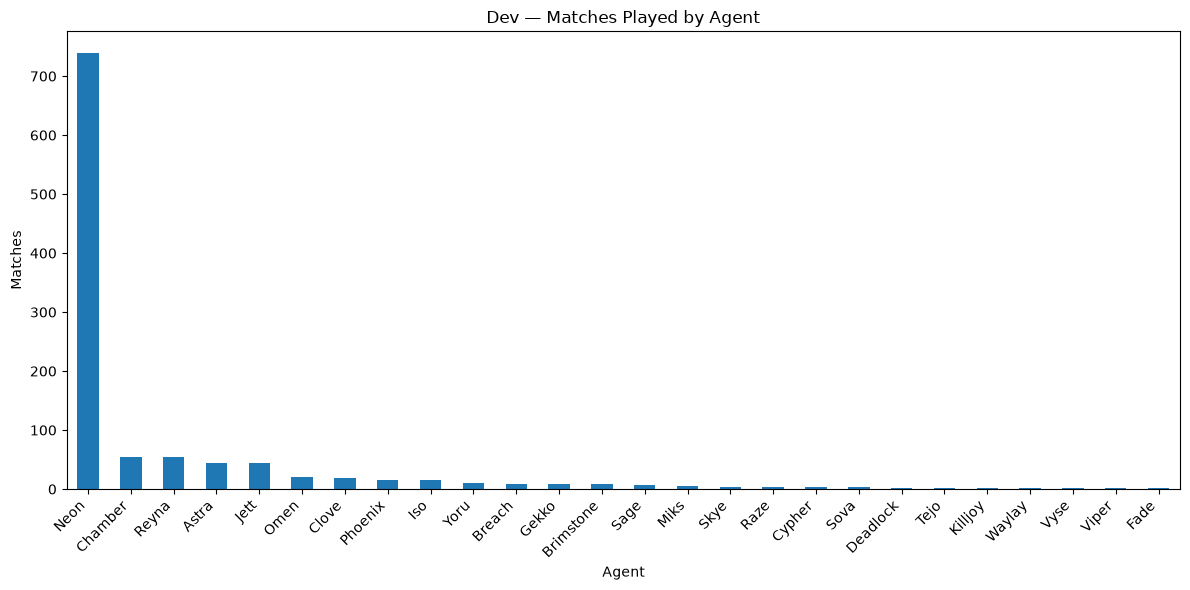

In [10]:
agent_counts = (
    df["Agent"]
    .value_counts()
)

display(
    agent_counts
    .rename("Matches")
    .to_frame()
)

plt.figure(figsize=(12, 6))
agent_counts.plot(kind="bar")
plt.title("Dev — Matches Played by Agent")
plt.xlabel("Agent")
plt.ylabel("Matches")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 6. Map usage

,Matches
Map,
Haven,157
Lotus,125
Split,105
Ascent,104
Bind,94
Breeze,93
Pearl,84
Corrode,84
Sunset,83


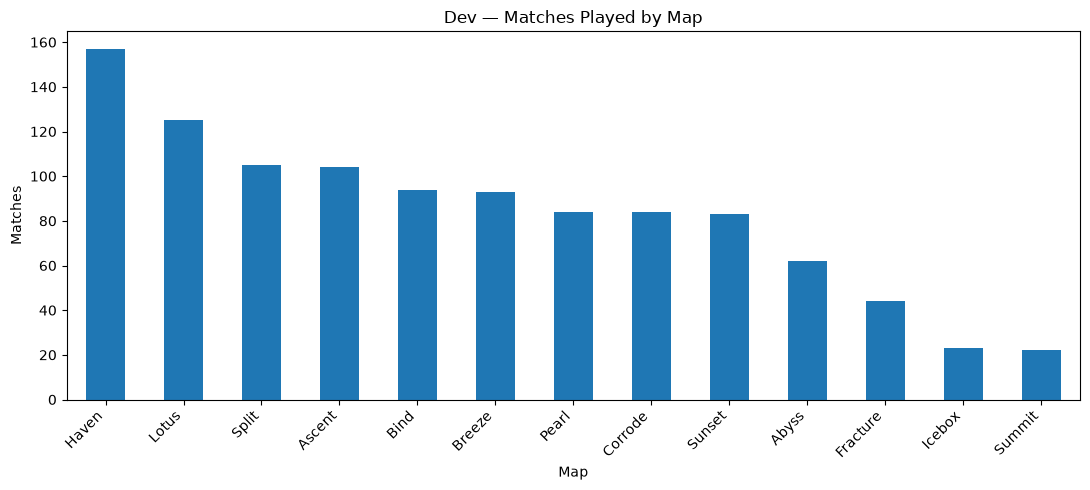

In [11]:
map_counts = (
    df["Map"]
    .value_counts()
)

display(
    map_counts
    .rename("Matches")
    .to_frame()
)

plt.figure(figsize=(11, 5))
map_counts.plot(kind="bar")
plt.title("Dev — Matches Played by Map")
plt.xlabel("Map")
plt.ylabel("Matches")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 7. Role-aware EDA

The raw dataset does not contain a Role column.

Role is therefore derived using the official Agent → Role mapping.

**Agent determines the role. ACS does not determine the role.**

In [12]:
AGENT_ROLE_MAP = {
    # Duelists
    "Iso": "Duelist",
    "Jett": "Duelist",
    "Neon": "Duelist",
    "Phoenix": "Duelist",
    "Raze": "Duelist",
    "Reyna": "Duelist",
    "Waylay": "Duelist",
    "Yoru": "Duelist",

    # Controllers
    "Astra": "Controller",
    "Brimstone": "Controller",
    "Clove": "Controller",
    "Harbor": "Controller",
    "Miks": "Controller",
    "Omen": "Controller",
    "Viper": "Controller",

    # Initiators
    "Breach": "Initiator",
    "Fade": "Initiator",
    "Gekko": "Initiator",
    "KAY/O": "Initiator",
    "Skye": "Initiator",
    "Sova": "Initiator",
    "Tejo": "Initiator",

    # Sentinels
    "Chamber": "Sentinel",
    "Cypher": "Sentinel",
    "Deadlock": "Sentinel",
    "Killjoy": "Sentinel",
    "Sage": "Sentinel",
    "Veto": "Sentinel",
    "Vyse": "Sentinel",
}

df["Role"] = (
    df["Agent"]
    .map(AGENT_ROLE_MAP)
)

unknown_agents = (
    df.loc[
        df["Role"].isna(),
        "Agent",
    ]
    .dropna()
    .unique()
    .tolist()
)

print("Unknown agents:", unknown_agents)

role_distribution = (
    df["Role"]
    .value_counts(dropna=False)
)

display(
    role_distribution
    .rename("Matches")
    .to_frame()
)

Unknown agents: []


,Matches
Role,
Duelist,885
Controller,98
Sentinel,69
Initiator,28


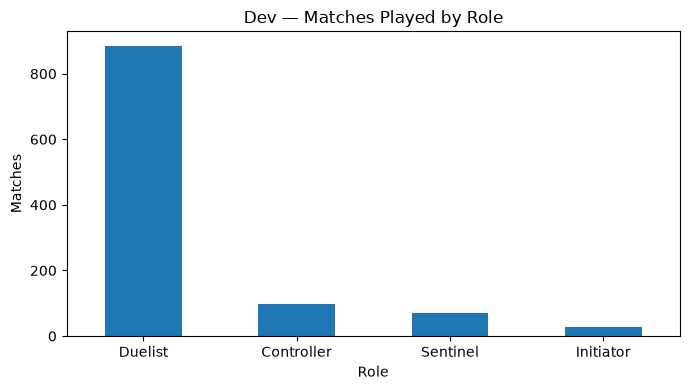

In [13]:
role_counts = (
    df["Role"]
    .value_counts()
)

plt.figure(figsize=(7, 4))
role_counts.plot(kind="bar")
plt.title("Dev — Matches Played by Role")
plt.xlabel("Role")
plt.ylabel("Matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Performance by Agent

Win rate is calculated using Win/Loss matches only. Draws are excluded from
the denominator.

In [14]:
binary_df = (
    df[df["Result"].isin(["Win", "Loss"])]
    .copy()
)

binary_df["Win"] = (
    binary_df["Result"] == "Win"
).astype(int)

agent_performance = (
    binary_df
    .groupby("Agent")
    .agg(
        Matches=("Match id", "count"),
        Wins=("Win", "sum"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
        Avg_DD_Delta=("DDΔ", "mean"),
    )
    .sort_values(
        ["Win_Rate", "Matches"],
        ascending=[False, False],
    )
)

display(
    agent_performance.style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
            "Avg_DD_Delta": "{:.1f}",
        }
    )
)

,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS,Avg_DD_Delta
Agent,,,,,,
Cypher,3,3,100.00%,1.06,245.0,4.0
Fade,1,1,100.00%,1.25,242.0,12.0
Vyse,1,1,100.00%,1.08,171.0,-5.0
Breach,9,5,55.56%,0.80,174.7,-24.2
Chamber,53,29,54.72%,1.22,235.7,14.4
Astra,44,23,52.27%,1.13,219.5,8.3
Neon,722,362,50.14%,1.13,239.9,4.3
Reyna,54,27,50.00%,1.15,227.9,0.5
Clove,18,9,50.00%,0.89,224.9,-18.8


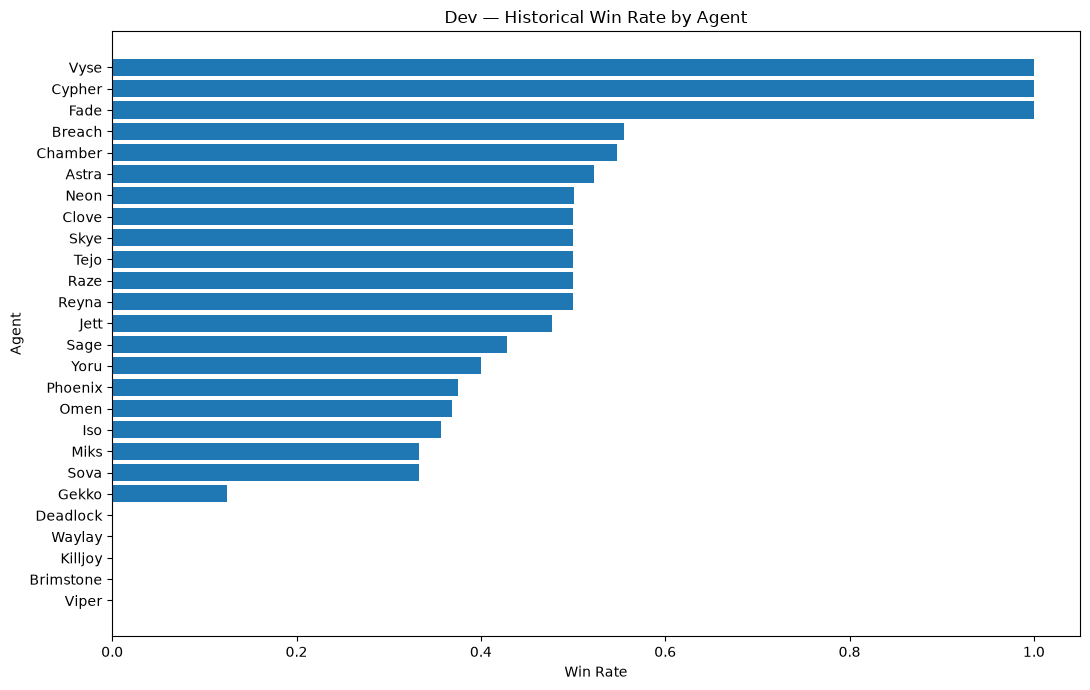

In [15]:
agent_plot = (
    agent_performance
    .sort_values("Win_Rate")
)

plt.figure(figsize=(11, 7))
plt.barh(
    agent_plot.index,
    agent_plot["Win_Rate"],
)
plt.title("Dev — Historical Win Rate by Agent")
plt.xlabel("Win Rate")
plt.ylabel("Agent")
plt.tight_layout()
plt.show()

## 9. Performance by Map

In [16]:
map_performance = (
    binary_df
    .groupby("Map")
    .agg(
        Matches=("Match id", "count"),
        Wins=("Win", "sum"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
        Avg_DD_Delta=("DDΔ", "mean"),
    )
    .sort_values(
        ["Win_Rate", "Matches"],
        ascending=[False, False],
    )
)

display(
    map_performance.style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
            "Avg_DD_Delta": "{:.1f}",
        }
    )
)

,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS,Avg_DD_Delta
Map,,,,,,
Icebox,23,16,69.57%,1.16,224.3,0.6
Summit,22,15,68.18%,1.05,241.1,1.2
Sunset,80,48,60.00%,1.18,244.9,13.5
Bind,93,50,53.76%,1.17,245.3,6.7
Pearl,83,42,50.60%,1.03,221.0,-4.3
Breeze,87,43,49.43%,1.18,241.2,9.0
Fracture,43,21,48.84%,1.09,229.2,-1.8
Lotus,123,58,47.15%,1.08,225.9,-0.2
Split,104,49,47.12%,1.15,243.6,4.9


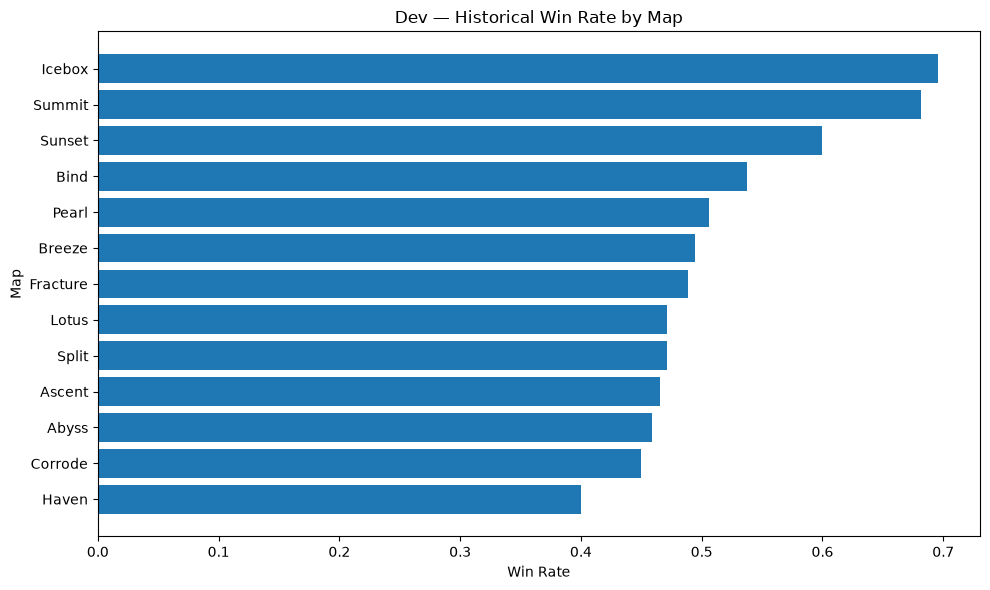

In [17]:
map_plot = (
    map_performance
    .sort_values("Win_Rate")
)

plt.figure(figsize=(10, 6))
plt.barh(
    map_plot.index,
    map_plot["Win_Rate"],
)
plt.title("Dev — Historical Win Rate by Map")
plt.xlabel("Win Rate")
plt.ylabel("Map")
plt.tight_layout()
plt.show()

## 10. Performance by Role

In [18]:
role_performance = (
    binary_df
    .groupby("Role")
    .agg(
        Matches=("Match id", "count"),
        Wins=("Win", "sum"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
    )
    .sort_values(
        ["Win_Rate", "Matches"],
        ascending=[False, False],
    )
)

display(
    role_performance.style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
        }
    )
)

,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS
Role,,,,,
Sentinel,67,36,53.73%,1.19,229.6
Duelist,865,427,49.36%,1.12,238.1
Controller,96,41,42.71%,1.01,216.2
Initiator,27,11,40.74%,0.96,188.1


## 11. Agent × Map analysis

This section looks at the combinations Dev has actually played.

Very small samples should be interpreted carefully.

In [19]:
agent_map_performance = (
    binary_df
    .groupby(["Agent", "Map"])
    .agg(
        Matches=("Match id", "count"),
        Wins=("Win", "sum"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
    )
    .reset_index()
    .sort_values(
        ["Matches", "Win_Rate"],
        ascending=[False, False],
    )
)

display(
    agent_map_performance
    .head(40)
    .style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
        }
    )
)

,Agent,Map,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS
85,Neon,Haven,110,44,40.00%,1.09,238.3
81,Neon,Bind,75,41,54.67%,1.20,255.1
89,Neon,Split,75,34,45.33%,1.18,252.1
87,Neon,Lotus,71,34,47.89%,1.05,225.3
80,Neon,Ascent,63,29,46.03%,1.08,236.7
88,Neon,Pearl,59,33,55.93%,1.03,223.4
82,Neon,Breeze,58,31,53.45%,1.24,246.8
83,Neon,Corrode,55,26,47.27%,1.18,243.4
91,Neon,Sunset,53,32,60.38%,1.23,252.5
79,Neon,Abyss,42,19,45.24%,1.12,235.2


In [20]:
stable_agent_map = (
    agent_map_performance[
        agent_map_performance["Matches"] >= 5
    ]
    .sort_values(
        ["Win_Rate", "Matches"],
        ascending=[False, False],
    )
)

print(
    "Agent × Map combinations with at least 5 matches:",
    len(stable_agent_map),
)

display(
    stable_agent_map
    .head(30)
    .style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
        }
    )
)

Agent × Map combinations with at least 5 matches: 30


,Agent,Map,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS
93,Omen,Bind,6,5,83.33%,1.02,200.3
90,Neon,Summit,14,10,71.43%,1.02,227.4
10,Astra,Sunset,7,5,71.43%,1.31,259.6
86,Neon,Icebox,20,14,70.00%,1.05,226.7
70,Jett,Lotus,8,5,62.50%,1.20,255.6
91,Neon,Sunset,53,32,60.38%,1.23,252.5
121,Reyna,Split,5,3,60.00%,1.33,279.6
28,Chamber,Corrode,7,4,57.14%,1.27,233.6
30,Chamber,Haven,7,4,57.14%,1.40,240.3
72,Jett,Split,7,4,57.14%,1.00,237.6


## 12. Performance distributions

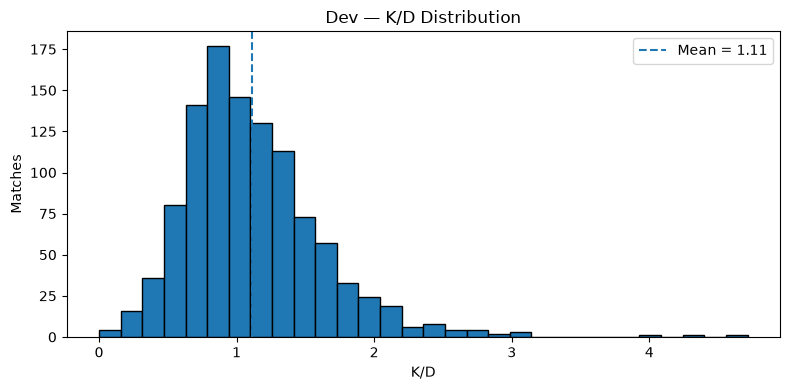

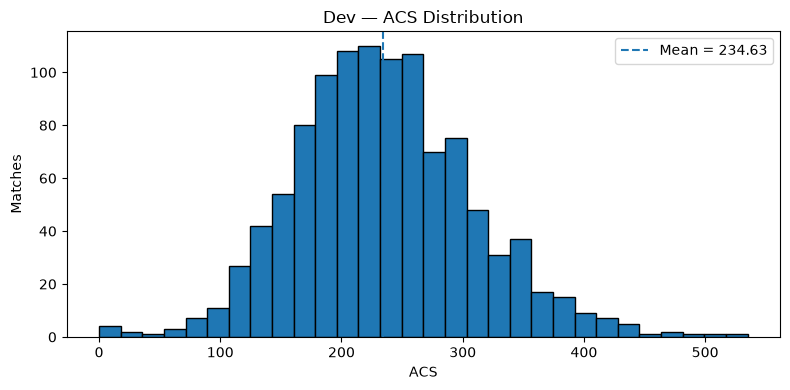

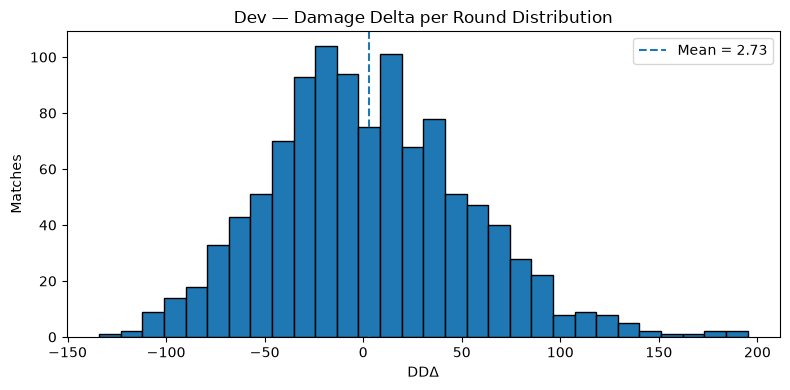

In [21]:
metrics = [
    ("K/D", "K/D Distribution"),
    ("ACS", "ACS Distribution"),
    ("DDΔ", "Damage Delta per Round Distribution"),
]

for column, title in metrics:

    values = pd.to_numeric(
        df[column],
        errors="coerce",
    ).dropna()

    plt.figure(figsize=(8, 4))
    plt.hist(
        values,
        bins=30,
        edgecolor="black",
    )

    plt.axvline(
        values.mean(),
        linestyle="--",
        label=f"Mean = {values.mean():.2f}",
    )

    plt.title(
        f"Dev — {title}"
    )

    plt.xlabel(column)
    plt.ylabel("Matches")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 13. Wins vs Losses performance comparison

In [22]:
comparison_columns = [
    "Kills",
    "Deaths",
    "Assists",
    "K/D",
    "ACS",
    "DDΔ",
    "HS%",
    "Score Margin",
]

result_comparison = (
    df[df["Result"].isin(["Win", "Loss"])]
    .groupby("Result")[comparison_columns]
    .mean(numeric_only=True)
    .T
)

display(
    result_comparison.style.format(
        "{:.2f}"
    )
)

Result,Loss,Win
Kills,15.66,19.12
Deaths,17.34,15.26
Assists,3.13,3.53
K/D,0.90,1.33
ACS,213.72,255.81
DDΔ,-17.26,23.11
HS%,0.25,0.27
Score Margin,-5.28,5.23


## 14. Numerical correlations

Correlation is descriptive and does not imply causation.

`TRS` is shown here only because it exists in the raw dataset. It should not
be passed into the final pre-match ML pipeline.

In [23]:
correlation_columns = [
    "Kills",
    "Deaths",
    "Assists",
    "K/D",
    "Kills/Round",
    "Deaths/Round",
    "Assists/Round",
    "DDΔ",
    "HS%",
    "ACS",
    "TRS",
    "Score Margin",
    "Win Flag",
]

correlation_columns = [
    column
    for column in correlation_columns
    if column in df.columns
]

correlation_df = (
    df[correlation_columns]
    .apply(
        pd.to_numeric,
        errors="coerce",
    )
    .corr()
)

display(
    correlation_df.round(2)
)

,Kills,Deaths,Assists,K/D,Kills/Round,Deaths/Round,Assists/Round,DDΔ,HS%,ACS,TRS,Score Margin,Win Flag
Kills,1.00,0.22,0.13,0.71,0.85,-0.22,-0.00,0.75,0.15,0.84,0.76,0.29,0.25
Deaths,0.22,1.00,0.24,-0.43,-0.20,0.65,0.02,-0.36,-0.07,-0.14,-0.26,-0.29,-0.29
Assists,0.13,0.24,1.00,-0.03,-0.01,0.03,0.94,0.06,-0.10,0.06,0.16,0.11,0.07
K/D,0.71,-0.43,-0.03,1.00,0.90,-0.61,0.01,0.90,0.19,0.85,0.85,0.49,0.42
Kills/Round,0.85,-0.20,-0.01,0.90,1.00,-0.31,0.00,0.89,0.19,0.98,0.88,0.39,0.33
Deaths/Round,-0.22,0.65,0.03,-0.61,-0.31,1.00,0.01,-0.56,-0.07,-0.24,-0.47,-0.51,-0.42
Assists/Round,-0.00,0.02,0.94,0.01,0.00,0.01,1.00,0.10,-0.09,0.08,0.17,0.13,0.09
DDΔ,0.75,-0.36,0.06,0.90,0.89,-0.56,0.10,1.00,0.19,0.89,0.90,0.45,0.38
HS%,0.15,-0.07,-0.10,0.19,0.19,-0.07,-0.09,0.19,1.00,0.16,0.16,0.10,0.10
ACS,0.84,-0.14,0.06,0.85,0.98,-0.24,0.08,0.89,0.16,1.00,0.87,0.32,0.27


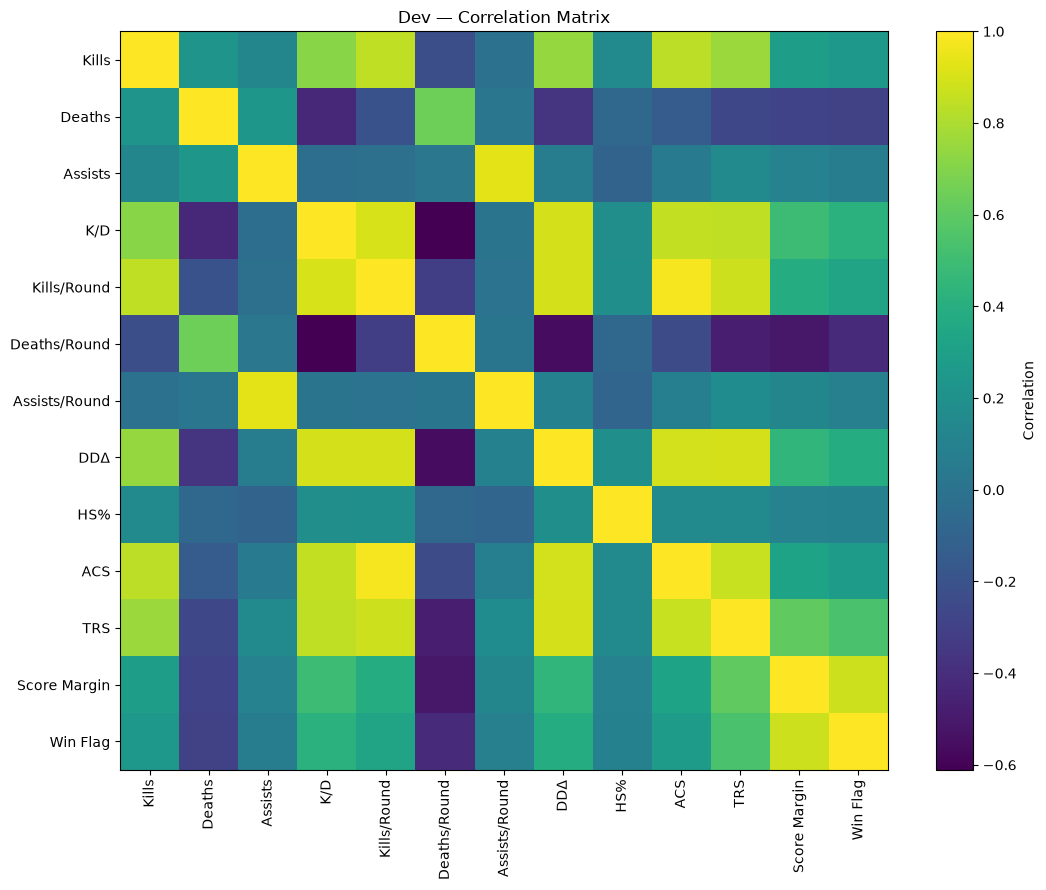

In [24]:
fig, ax = plt.subplots(
    figsize=(11, 9)
)

image = ax.imshow(
    correlation_df.values,
    aspect="auto",
)

ax.set_xticks(
    range(len(correlation_df.columns))
)
ax.set_yticks(
    range(len(correlation_df.index))
)

ax.set_xticklabels(
    correlation_df.columns,
    rotation=90,
)
ax.set_yticklabels(
    correlation_df.index,
)

ax.set_title(
    "Dev — Correlation Matrix"
)

fig.colorbar(
    image,
    ax=ax,
    label="Correlation",
)

plt.tight_layout()
plt.show()

## 15. Monthly performance trend

In [25]:
monthly = (
    binary_df
    .set_index("Date")
    .resample("MS")
    .agg(
        Matches=("Match id", "count"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
    )
)

monthly = (
    monthly[
        monthly["Matches"] > 0
    ]
)

display(
    monthly.style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
        }
    )
)

,Matches,Win_Rate,Avg_KD,Avg_ACS
Date,,,,
2025-06-01 00:00:00,32,59.38%,1.04,205.4
2025-07-01 00:00:00,64,59.38%,1.13,241.1
2025-08-01 00:00:00,94,51.06%,1.11,232.4
2025-09-01 00:00:00,82,45.12%,1.10,223.6
2025-10-01 00:00:00,16,31.25%,1.26,252.4
2025-11-01 00:00:00,33,45.45%,1.10,228.2
2025-12-01 00:00:00,85,42.35%,1.09,234.4
2026-01-01 00:00:00,80,47.50%,1.10,237.5
2026-02-01 00:00:00,53,50.94%,1.10,232.7


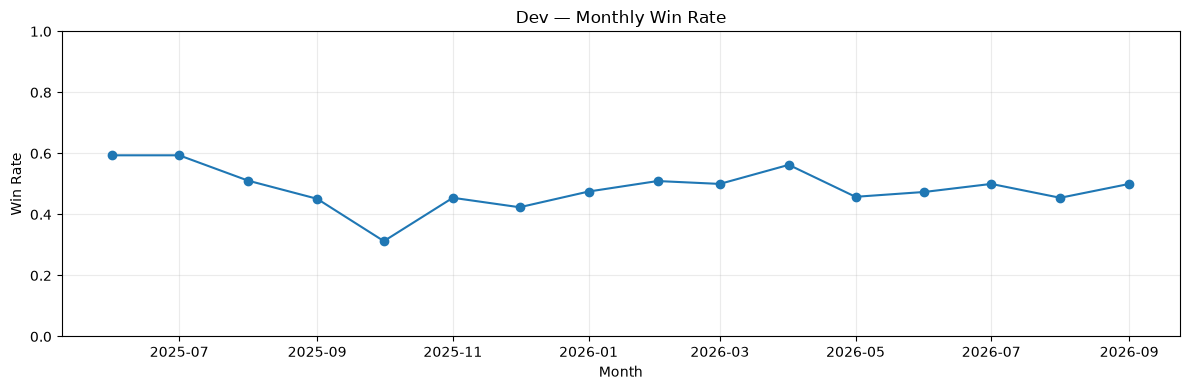

In [26]:
plt.figure(figsize=(12, 4))

plt.plot(
    monthly.index,
    monthly["Win_Rate"],
    marker="o",
)

plt.title(
    "Dev — Monthly Win Rate"
)

plt.xlabel("Month")
plt.ylabel("Win Rate")
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 16. Highest and lowest K/D matches

In [27]:
display_columns = [
    "Date",
    "Map",
    "Agent",
    "Role",
    "Result",
    "Kills",
    "Deaths",
    "Assists",
    "K/D",
    "ACS",
    "DDΔ",
]

print("Highest K/D matches:")
display(
    df.nlargest(
        10,
        "K/D",
    )[display_columns]
)

print("\nLowest K/D matches:")
display(
    df.nsmallest(
        10,
        "K/D",
    )[display_columns]
)

Highest K/D matches:


,Date,Map,Agent,Role,Result,Kills,Deaths,Assists,K/D,ACS,DDΔ
576,2026-03-14,Corrode,Neon,Duelist,Win,33,7,1,4.714286,421,166
959,2026-07-04,Lotus,Neon,Duelist,Win,34,8,4,4.250000,508,183
4,2025-06-22,Icebox,Skye,Initiator,Win,4,1,0,4.000000,230,72
551,2026-03-03,Abyss,Neon,Duelist,Win,24,8,1,3.000000,434,128
778,2026-05-22,Lotus,Reyna,Duelist,Win,12,4,6,3.000000,243,56
866,2026-06-14,Fracture,Neon,Duelist,Win,24,8,2,3.000000,361,127
744,2026-05-16,Split,Yoru,Duelist,Win,29,10,3,2.900000,405,136
164,2025-08-23,Sunset,Neon,Duelist,Win,26,9,4,2.888889,427,146
552,2026-03-03,Split,Neon,Duelist,Win,42,15,4,2.800000,468,157
902,2026-06-25,Haven,Neon,Duelist,Loss,42,15,6,2.800000,535,191



Lowest K/D matches:


,Date,Map,Agent,Role,Result,Kills,Deaths,Assists,K/D,ACS,DDΔ
800,2026-05-25,Haven,Jett,Duelist,Loss,0,10,0,0.000000,5,-98
822,2026-06-03,Haven,Astra,Controller,Loss,0,1,0,0.000000,0,-5
1024,2026-08-01,Lotus,Neon,Duelist,Loss,0,1,0,0.000000,0,-9
927,2026-06-29,Split,Brimstone,Controller,Loss,1,13,1,0.076923,20,-134
473,2026-01-27,Haven,Neon,Duelist,Loss,3,15,3,0.200000,58,-116
216,2025-09-13,Ascent,Astra,Controller,Loss,3,14,1,0.214286,56,-103
322,2025-11-29,Sunset,Neon,Duelist,Loss,3,14,0,0.214286,64,-111
847,2026-06-10,Breeze,Reyna,Duelist,Loss,3,14,6,0.214286,72,-111
537,2026-02-19,Breeze,Brimstone,Controller,Loss,4,17,4,0.235294,86,-107
272,2025-09-27,Bind,Astra,Controller,Loss,5,19,10,0.263158,99,-100


## 17. Dev Dataset Summary

Dev's dataset contains a much larger Competitive history than the first
player dataset and is strongly concentrated around Duelist gameplay,
especially Neon.

Important modelling implications:

1. Agent usage is highly imbalanced, so frequent agents will have much richer
   historical information than rarely used agents.
2. Role usage is also imbalanced, which supports the final **Top 2 agents per
   role** recommendation design.
3. Map history is substantial enough to support personalized map-aware
   historical features.
4. Agent × Map combinations with very small samples should still be treated
   cautiously.
5. Current-match K/D, ACS, kills, deaths, DDΔ and TRS are useful for EDA but
   cannot be used directly as pre-match model inputs.
6. The later feature-engineering pipeline should create only
   **historical, leakage-free versions** of performance information.

The next stage is the common cleaning and historical feature-engineering
pipeline, followed by separate Logistic Regression, Random Forest and
CatBoost modelling notebooks.